In [16]:
import sys
import os
sys.path.insert(0, os.path.abspath("../.."))

import json
import csv
from os import path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from web3 import Web3
w3 = Web3(Web3.HTTPProvider('https://eth-mainnet.g.alchemy.com/v2/<key>'))
from web3.logs import STRICT, IGNORE, DISCARD, WARN
from eth_abi import decode

from compounds_research import settings

In [17]:
w3.HTTPProvider('http:satoshi.doc.ic.ac.uk:8545')

In [18]:
# dydx margin solo contract
dydx_solo = '0x1E0447b19BB6EcFdAe1e4AE1694b0C3659614e4e'

In [19]:
with open(path.join(settings.PROJECT_ROOT, 'misc', 'dydx-solo-abi.json')) as json_file:
    solo_abi = json.load(json_file)

In [20]:
contract = w3.eth.contract(address=dydx_solo, abi=solo_abi['contracts']['contract.sol:Events']['abi'])

In [21]:
tokens = {
    'DAI': '0x6B175474E89094C44Da98b954EedeAC495271d0F',
    'WETH': '0xC02aaA39b223FE8D0A0e5C4F27eAD9083C756Cc2',
    'SAI': '0x89d24A6b4CcB1B6fAA2625fE562bDD9a23260359',
    'USDC': '0xA0b86991c6218b36c1d19D4a2e9Eb0cE3606eB48'
}

dydx_market_ids = {
    'DAI': 3,
    'WETH': 0,
    'SAI': 1,
    'USDC': 2
}

In [22]:
blocktimes = pd.read_csv(path.join(settings.DATA_PATH, 'dydx', 'eth_block_times.csv.gz'))

def load_data(filename: str):
    df = pd.read_csv(path.join(settings.DATA_PATH, 'dydx', filename))
    df = df.set_index('block_height').join(blocktimes.set_index('block_height'))
    df['datetime'] = pd.to_datetime(df['timestamp'], unit='s')
    del df['timestamp']
    return df

In [23]:
df_dai = load_data('dai_market_dydx.csv.gz')
df_weth = load_data('weth_market_dydx.csv.gz')
df_usdc = load_data('usdc_market_dydx.csv.gz')


In [24]:
for symbol, df in {"dai": df_dai, "weth": df_weth, "usdc": df_usdc}.items():
    print(symbol, df["supply_amount"].median() / 1e24)

dai 4.654914589649647
weth 0.09437596323630135
usdc 6.7063386370190004e-12


In [25]:
def plot_rate(df, title=None):
    seconds_per_year = 3600 * 24 * 365
    fig, ax1 = plt.subplots()
    ax2 = ax1.twinx()
    lns1 = ax1.plot(df['datetime'], df['interest_rate']/1e18 * seconds_per_year, color='steelblue', label='Interest Rate')
    lns2 = ax2.plot(df['datetime'], df['utilization'], linestyle=':', color='lightsteelblue', label='Utilization')
    #These charts look so good
    lns = lns1+lns2
    labs = [l.get_label() for l in lns]
    ax1.legend(lns, labs)
    if title is not None:
        ax1.set_title(title)
    
    ax1.set_ylabel('Borrow Interest Rate (APR)')
    ax1.set_xlabel('Block Number')
    ax2.set_ylabel('Utilization')

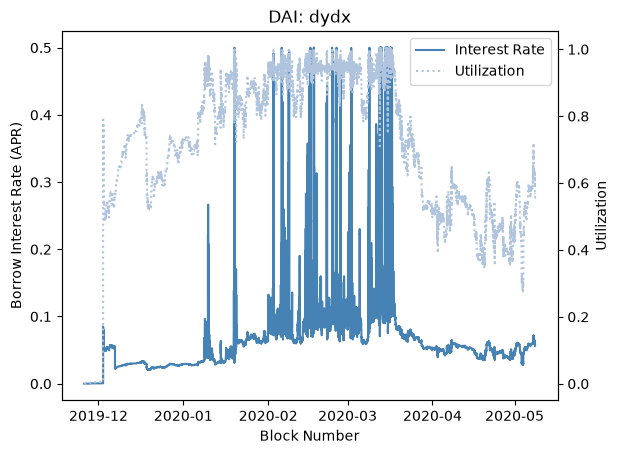

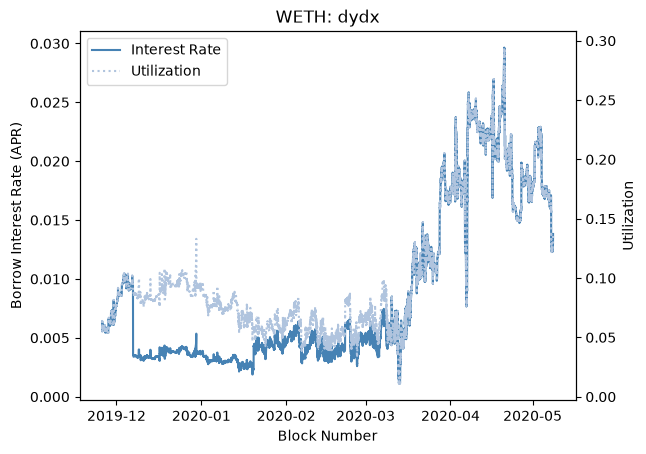

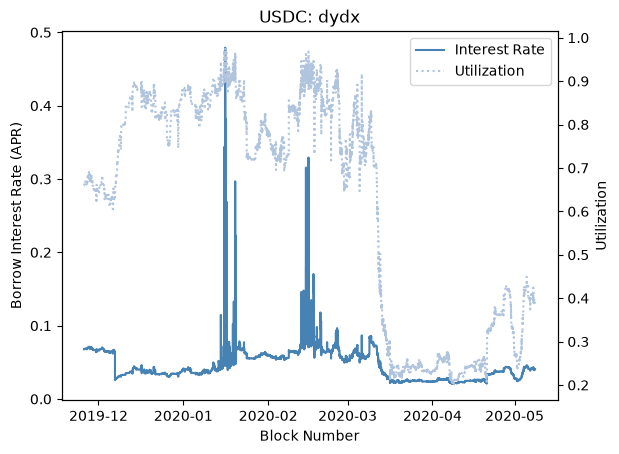

In [26]:
plot_rate(df_dai, title='DAI: dydx')
plot_rate(df_weth, title='WETH: dydx')
plot_rate(df_usdc, title='USDC: dydx')


In [27]:
def getInterestRates(token, fromBlock=9000000, toBlock=w3.eth.block_number, file='_dydx.csv'):
    assert fromBlock <= toBlock, 'Invalid block range specified.'
    dydx = w3.eth.contract(address=dydx_solo, abi=solo_abi['contracts']['contract.sol:Getters']['abi'])
    market_id = dydx_market_ids[token.upper()]
    token_address = tokens[token.upper()]
    height = fromBlock
    
    with open(token.lower()+'_'+file, 'w', newline='') as csvfile:
        fieldnames = ['block_height', 'token_address', 'interest_rate', 'borrow_amount', 'supply_amount', 'utilization']
        writer = csv.DictWriter(csvfile, fieldnames=fieldnames)
        writer.writeheader()
    
        while height <= toBlock:
            market_info = dydx.functions.getMarketWithInfo(market_id).call(block_identifier=height)
            assert tokens[token] == market_info[0][0]
            interest_rate = market_info[3][0]
            borrow = market_info[0][1][0]
            supply = market_info[0][1][1]
            utilization = round(borrow/supply, 5) if supply != 0 else 0
            writer.writerow({
                'block_height': height, 
                'token_address': token_address, 
                'interest_rate': interest_rate,
                'borrow_amount': borrow,
                'supply_amount': supply,
                'utilization': utilization
            })
            #print(height, interest_rate, borrow, supply, utilization)
            height += 1

In [31]:
def write_block_times(fromBlock=9000000, toBlock=w3.eth.block_number, file='eth_block_times.csv'):
    assert fromBlock <= toBlock, 'Invalid block range specified.' 
    with open(file, 'w', newline='') as csvfile:
        fieldnames = ['block_height', 'timestamp']
        writer = csv.DictWriter(csvfile, fieldnames=fieldnames)
        writer.writeheader()
        counter = 0
        while fromBlock <= toBlock:
            timestamp = w3.eth.getBlock(fromBlock)['timestamp']
            if counter % 10000 == 0:
                pass
                #print(round(counter/(toBlock-fromBlock)*100, 2), '% of blocks parsed')
            writer.writerow({
                    'block_height': fromBlock, 
                    'timestamp': timestamp
            })
            fromBlock += 1
            counter += 1

In [32]:
solo_abi['contracts']

{'contract.sol:Account': {'abi': '[]'},
 'contract.sol:Actions': {'abi': '[]'},
 'contract.sol:Admin': {'abi': '[{"constant":false,"inputs":[{"name":"marketId","type":"uint256"},{"components":[{"name":"value","type":"uint256"}],"name":"spreadPremium","type":"tuple"}],"name":"ownerSetSpreadPremium","outputs":[],"payable":false,"stateMutability":"nonpayable","type":"function"},{"constant":false,"inputs":[{"name":"marketId","type":"uint256"},{"name":"interestSetter","type":"address"}],"name":"ownerSetInterestSetter","outputs":[],"payable":false,"stateMutability":"nonpayable","type":"function"},{"constant":false,"inputs":[{"name":"token","type":"address"},{"name":"recipient","type":"address"}],"name":"ownerWithdrawUnsupportedTokens","outputs":[{"name":"","type":"uint256"}],"payable":false,"stateMutability":"nonpayable","type":"function"},{"constant":false,"inputs":[{"components":[{"name":"value","type":"uint256"}],"name":"minBorrowedValue","type":"tuple"}],"name":"ownerSetMinBorrowedValue"

In [36]:
#eventFilter = contract.events.LogIndexUpdate.createFilter(fromBlock=9948410, toBlock=9949910)
event_signature = contract.events.LogIndexUpdate().event_abi
logs = w3.eth.get_logs({
    'address': dydx_solo,
    'fromBlock': 9948410,
    'toBlock': 9949910,
    'topics': [w3.keccak(text="LogIndexUpdate(uint256,(uint96,uint96,uint32))").hex()]
})

AttributeError: 'LogIndexUpdate(uint256,(uint96,uint96,uint32))' object has no attribute 'event_abi'

In [ ]:
decode_single('(uint256,uint256,bool,uint256,bool,uint128,address)', bytes.fromhex('00000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000100000000000000000000000000000000000000000000000037e2597f4e24462d00000000000000000000000000000000000000000000000000000000000000010000000000000000000000000000000000000000000000004616280dd3afccf5000000000000000000000000a8b39829ce2246f89b31c013b8cde15506fb9a76'))